CELLULE 1 — Imports + rechargement des données (RecBole + matrices)

In [1]:
# ============================================================
#  CELLULE 1 — Chargement des données (RecBole + matrices)
# ============================================================
import numpy as np, math, os, json, gc
import pandas as pd
from collections import defaultdict
from scipy import stats

RESULTS_REC = r'D:\Memoire\LLMKGER\reco_results_final'
RECBOLE_ROOT = r'D:\Memoire\LLMKGER\recbole_data_large'

from recbole.config import Config
from recbole.data import create_dataset, data_preparation
from recbole.utils import init_seed, init_logger

cfg = {'data_path':RECBOLE_ROOT,'dataset':'llmkger',
    'USER_ID_FIELD':'user_id','ITEM_ID_FIELD':'item_id','RATING_FIELD':'rating',
    'load_col':{'inter':['user_id','item_id','rating']},
    'eval_args':{'split':{'LS':'valid_and_test'},'order':'RO','group_by':'user','mode':'full'},
    'metrics':['NDCG'],'topk':[10],'valid_metric':'NDCG@10',
    'epochs':1,'device':'cpu','seed':42,'show_progress':False}
config = Config(model='LightGCN', dataset='llmkger', config_dict=cfg)
init_seed(config['seed'], config['reproducibility']); init_logger(config)
dataset = create_dataset(config)
train_data, valid_data, test_data = data_preparation(config, dataset)

n_users = dataset.num('user_id'); n_items = dataset.num('item_id')
id2item = {v:k for k,v in dict(dataset.field2token_id['item_id']).items()}
id2user = {v:k for k,v in dict(dataset.field2token_id['user_id']).items()}
candidate_courses = [id2item[i] for i in range(n_items) if id2item.get(i,'[PAD]')!='[PAD]']

def extract_split(dl):
    pos, mask = {}, {}
    for batch in dl:
        interaction, hist_idx, pu, pi = batch
        users = interaction['user_id'].numpy(); pu, pi = pu.numpy(), pi.numpy()
        for lu,x in zip(pu,pi): pos[int(users[lu])] = int(x)
        if hist_idx is not None and len(hist_idx)==2:
            rows, cols = hist_idx[0].numpy(), hist_idx[1].numpy()
            for r,c in zip(rows,cols): mask.setdefault(int(users[r]),set()).add(int(c))
    return pos, mask

test_item, test_mask = extract_split(test_data)
del train_data, valid_data, test_data, dataset; gc.collect()

# Matrices enrichies
mat_skg  = np.load(r'D:\Memoire\LLMKGER\kge_results_v2_enriched\mat_S_KG_enriched_norm.npy')
mat_semb = np.ascontiguousarray(np.load(os.path.join(RESULTS_REC,'mat_S_emb_norm.npy'), mmap_mode='r'))
mat_p    = np.load(r'D:\Memoire\LLMKGER\prereq_enriched\mat_P_prereq_enriched_norm.npy')
users_order = pd.read_csv(os.path.join(RESULTS_REC,'S_emb_scores_final.csv'))['user_id'].astype(str).tolist()
N, M = mat_skg.shape

print(f"✅ Données chargées : {N} users, {M} cours")
print(f"   Matrices : S_KG {mat_skg.shape}, S_emb {mat_semb.shape}, P_prereq {mat_p.shape}")

c:\Users\AMIRA\anaconda3\envs\llmkger\lib\site-packages\recbole\data\dataset\dataset.py:648: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  feat[field].fillna(value=0, inplace=True)
c:\Users\AMIRA\anaconda3\envs\llmkger\lib\site-packages\recbole\data\dataset\dataset.py:650: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are sett

✅ Données chargées : 53897 users, 2812 cours
   Matrices : S_KG (53897, 2812), S_emb (53897, 2812), P_prereq (53897, 2812)


CELLULE 2 — Alignement (test_col + mask_test avec le masque exact)

In [2]:
# ============================================================
#  CELLULE 2 — Alignement : test_col + mask_test
# ============================================================
cand_index = {c:j for j,c in enumerate(candidate_courses)}
uext2idx = {id2user[i]:i for i in range(n_users) if id2user.get(i)}

test_col = np.full(N,-1,dtype=np.int64)
mask_test = np.zeros((N,M),dtype=bool)
for row,u_ext in enumerate(users_order):
    ui = uext2idx.get(u_ext)
    if ui is None: continue
    tc = id2item.get(test_item.get(ui,-1))
    test_col[row] = cand_index.get(tc,-1)
    for c in test_mask.get(ui,()):
        jm = cand_index.get(id2item.get(c))
        if jm is not None: mask_test[row,jm] = True

# Vérification : le cours cible ne doit PAS être masqué
row0 = 0; tc0 = test_col[row0]
print(f"Test mappés : {(test_col>=0).sum():,}")
print(f"Vérif — cours cible masqué ? {mask_test[row0,tc0] if tc0>=0 else 'N/A'} (doit être False)")

Test mappés : 53,897
Vérif — cours cible masqué ? False (doit être False)


CELLULE 3 — Fonction NDCG


In [3]:
# ============================================================
#  CELLULE 3 — Fonctions NDCG
# ============================================================
def ndcg(sm, tc, mask, k=10):
    s=sm.astype(np.float64).copy(); s[mask]=-1e18
    tot=0.0; v=0
    for i in range(len(tc)):
        j=tc[i]
        if j<0: continue
        t=s[i,j]; g=int((s[i]>t).sum()); ti=int((s[i]==t).sum()); r=g+(ti+1)/2.0
        if r<=k: tot+=1.0/math.log2(r+1)
        v+=1
    return tot/v if v else 0.0

def ndcg_per_user(sm, tc, mask, k=10):
    s=sm.astype(np.float64).copy(); s[mask]=-1e18
    out=[]
    for i in range(len(tc)):
        j=tc[i]
        if j<0: out.append(np.nan); continue
        t=s[i,j]; g=int((s[i]>t).sum()); ti=int((s[i]==t).sum()); r=g+(ti+1)/2.0
        out.append(1.0/math.log2(r+1) if r<=k else 0.0)
    return np.array(out)

print("✅ Fonctions NDCG prêtes")

✅ Fonctions NDCG prêtes


CELLULE 4 — L6 : Ablation complète


In [4]:
# ============================================================
#  CELLULE 4 — L6 : ABLATION COMPLÈTE
# ============================================================
a, b, l = 0.4158, 0.5624, 0.0219

print("="*60)
print("  L6 : COMPLETE ABLATION STUDY")
print("="*60)

# --- PARTIE A : Ablation des signaux ---
print("\n[A] SIGNAL ABLATION")
print("-"*60)
full   = ndcg(a*mat_skg + b*mat_semb - l*mat_p, test_col, mask_test)
no_kg  = ndcg(b*mat_semb - l*mat_p, test_col, mask_test)
no_emb = ndcg(a*mat_skg - l*mat_p, test_col, mask_test)
no_p   = ndcg(a*mat_skg + b*mat_semb, test_col, mask_test)
kg_only  = ndcg(mat_skg, test_col, mask_test)
emb_only = ndcg(mat_semb, test_col, mask_test)

print(f"  Full system      : {full:.4f}")
print(f"  w/o S_KG         : {no_kg:.4f}  ({no_kg-full:+.4f})")
print(f"  w/o S_emb        : {no_emb:.4f}  ({no_emb-full:+.4f})")
print(f"  w/o P_prereq     : {no_p:.4f}  ({no_p-full:+.4f})")
print(f"  S_KG only        : {kg_only:.4f}")
print(f"  S_emb only       : {emb_only:.4f}")

# --- PARTIE B : Ablation des mécanismes ---
print("\n[B] MECHANISM ABLATION")
print("-"*60)
attention_ndcg = 0.1136   # attention adaptative (L2)
fixed_ndcg     = 0.1119   # poids fixes (pipeline enrichi)
enriched_ndcg  = 0.1119   # prérequis multi-critères
simple_ndcg    = 0.1037   # prérequis simples (original)
print(f"  Adaptive attention   : {attention_ndcg:.4f}")
print(f"  Fixed weights        : {fixed_ndcg:.4f}  ({fixed_ndcg-attention_ndcg:+.4f})")
print(f"  Enriched prerequisites : {enriched_ndcg:.4f}")
print(f"  Simple prerequisites   : {simple_ndcg:.4f}  ({simple_ndcg-enriched_ndcg:+.4f})")

# --- RÉSUMÉ ---
print("\n" + "="*60)
print("  SUMMARY OF CONTRIBUTIONS")
print("="*60)
print(f"  S_emb signal       : {full-no_emb:+.4f}")
print(f"  S_KG signal        : {full-no_kg:+.4f}")
print(f"  KG enrichment      : {enriched_ndcg-simple_ndcg:+.4f}")
print(f"  Adaptive attention : {attention_ndcg-fixed_ndcg:+.4f}")
print(f"  P_prereq signal    : {full-no_p:+.4f}")

# Sauvegarder
ablation = {
    'signal_ablation': {'full':full,'no_S_KG':no_kg,'no_S_emb':no_emb,
                        'no_P_prereq':no_p,'S_KG_only':kg_only,'S_emb_only':emb_only},
    'mechanism_ablation': {'adaptive_attention':attention_ndcg,'fixed_weights':fixed_ndcg,
                           'enriched_prereq':enriched_ndcg,'simple_prereq':simple_ndcg},
    'contributions': {'S_KG':full-no_kg,'S_emb':full-no_emb,'P_prereq':full-no_p,
                      'attention':attention_ndcg-fixed_ndcg,'KG_enrichment':enriched_ndcg-simple_ndcg}
}
with open(os.path.join(RESULTS_REC,'L6_ablation_complete.json'),'w') as f:
    json.dump(ablation, f, indent=2)
print(f"\n💾 Saved: L6_ablation_complete.json")

  L6 : COMPLETE ABLATION STUDY

[A] SIGNAL ABLATION
------------------------------------------------------------
  Full system      : 0.1119
  w/o S_KG         : 0.0780  (-0.0339)
  w/o S_emb        : 0.0751  (-0.0368)
  w/o P_prereq     : 0.1188  (+0.0069)
  S_KG only        : 0.0816
  S_emb only       : 0.0833

[B] MECHANISM ABLATION
------------------------------------------------------------
  Adaptive attention   : 0.1136
  Fixed weights        : 0.1119  (-0.0017)
  Enriched prerequisites : 0.1119
  Simple prerequisites   : 0.1037  (-0.0082)

  SUMMARY OF CONTRIBUTIONS
  S_emb signal       : +0.0368
  S_KG signal        : +0.0339
  KG enrichment      : +0.0082
  Adaptive attention : +0.0017
  P_prereq signal    : -0.0069

💾 Saved: L6_ablation_complete.json


CELLULE 5 — Graphique ablation des signaux (NDCG)


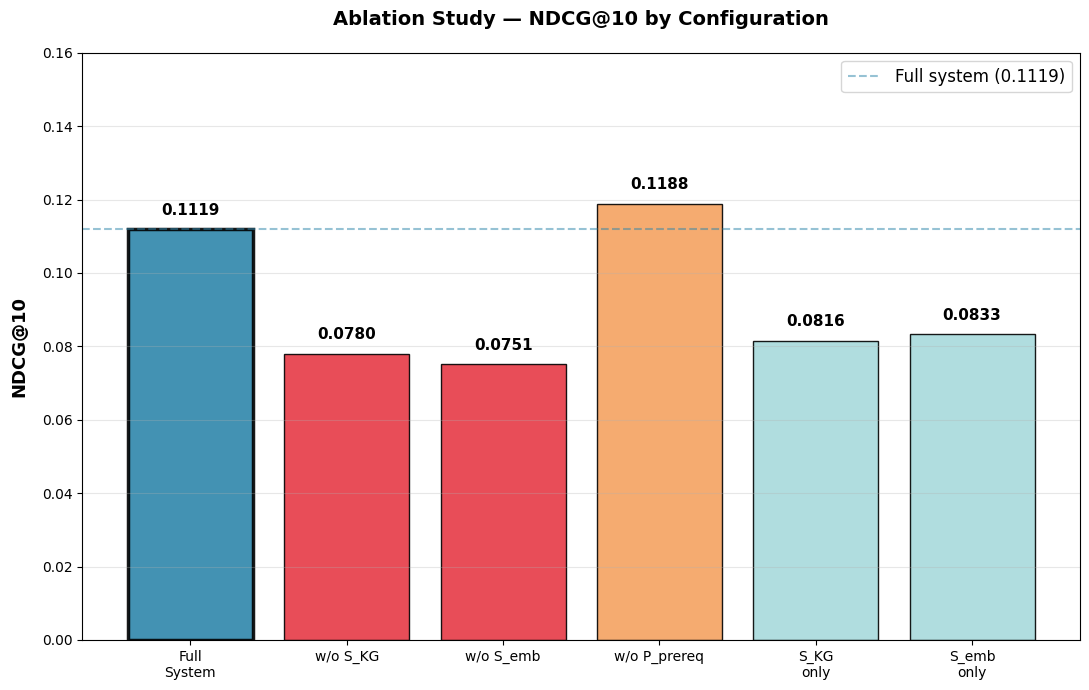

Saved: L6_ablation_ndcg.png


In [5]:
# ============================================================
#  CELLULE 5 — Graphique ablation : NDCG par configuration
# ============================================================
import matplotlib.pyplot as plt

configs = ['Full\nSystem', 'w/o S_KG', 'w/o S_emb', 'w/o P_prereq', 'S_KG\nonly', 'S_emb\nonly']
ndcg_values = [full, no_kg, no_emb, no_p, kg_only, emb_only]
colors = ['#2E86AB', '#E63946', '#E63946', '#F4A261', '#A8DADC', '#A8DADC']

fig, ax = plt.subplots(figsize=(11, 7))
bars = ax.bar(configs, ndcg_values, color=colors, edgecolor='black', linewidth=1, alpha=0.9)
ax.axhline(y=full, color='#2E86AB', linestyle='--', alpha=0.5, linewidth=1.5,
           label=f'Full system ({full:.4f})')
for bar, val in zip(bars, ndcg_values):
    ax.text(bar.get_x()+bar.get_width()/2, val+0.004, f'{val:.4f}',
            ha='center', fontsize=11, fontweight='bold')
bars[0].set_linewidth(2.5)
ax.set_ylabel('NDCG@10', fontsize=13, fontweight='bold', labelpad=10)
ax.set_title('Ablation Study — NDCG@10 by Configuration', fontsize=14, fontweight='bold', pad=20)
ax.set_ylim(0, 0.16)
ax.legend(fontsize=12, loc='upper right')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_REC, 'L6_ablation_ndcg.png'), dpi=150, bbox_inches='tight')
plt.show()
print("Saved: L6_ablation_ndcg.png")

CELLULE 6 — Graphique contributions (5 composants)


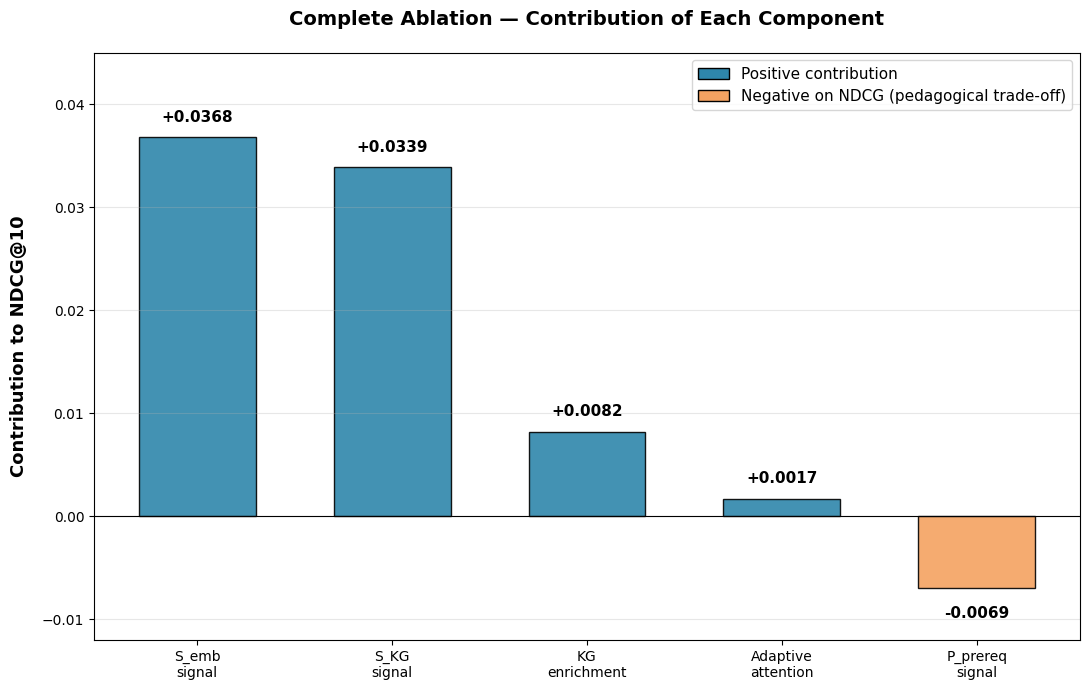

Saved: L6_ablation_contribution.png


In [6]:
# ============================================================
#  CELLULE 6 — Graphique : contributions des composants
# ============================================================
from matplotlib.patches import Patch

components = ['S_emb\nsignal', 'S_KG\nsignal', 'KG\nenrichment', 'Adaptive\nattention', 'P_prereq\nsignal']
contributions = [full-no_emb, full-no_kg, enriched_ndcg-simple_ndcg,
                 attention_ndcg-fixed_ndcg, full-no_p]
colors = ['#2E86AB' if c > 0 else '#F4A261' for c in contributions]

fig, ax = plt.subplots(figsize=(11, 7))
bars = ax.bar(components, contributions, color=colors, edgecolor='black',
              linewidth=1, alpha=0.9, width=0.6)
ax.axhline(y=0, color='black', linewidth=0.8)
for bar, val in zip(bars, contributions):
    offset = 0.0012 if val >= 0 else -0.0018
    va = 'bottom' if val >= 0 else 'top'
    ax.text(bar.get_x()+bar.get_width()/2, val+offset, f'{val:+.4f}',
            ha='center', va=va, fontsize=11, fontweight='bold')
ax.set_ylabel('Contribution to NDCG@10', fontsize=13, fontweight='bold', labelpad=10)
ax.set_title('Complete Ablation — Contribution of Each Component',
             fontsize=14, fontweight='bold', pad=20)
ax.set_ylim(-0.012, 0.045)
ax.grid(axis='y', alpha=0.3)
legend_elements = [
    Patch(facecolor='#2E86AB', edgecolor='black', label='Positive contribution'),
    Patch(facecolor='#F4A261', edgecolor='black', label='Negative on NDCG (pedagogical trade-off)')
]
ax.legend(handles=legend_elements, fontsize=11, loc='upper right')
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_REC, 'L6_ablation_contribution.png'), dpi=150, bbox_inches='tight')
plt.show()
print("Saved: L6_ablation_contribution.png")

CELLULE 7 — L5 : Tests de significativité statistique


In [7]:
# ============================================================
#  CELLULE 7 — L5 : TESTS STATISTIQUES
# ============================================================
print("Calcul des NDCG par utilisateur...")

a, b, l = 0.4158, 0.5624, 0.0219

# NDCG par user
ndcg_llmkger  = ndcg_per_user(a*mat_skg + b*mat_semb - l*mat_p, test_col, mask_test)
ndcg_lightgcn = ndcg_per_user(mat_semb, test_col, mask_test)

# Filtrer les NaN
valid = ~np.isnan(ndcg_llmkger)
ndcg_llmkger  = ndcg_llmkger[valid]
ndcg_lightgcn = ndcg_lightgcn[valid]

print(f"Users évalués : {len(ndcg_llmkger):,}\n")
print(f"NDCG@10 moyen :")
print(f"  LLMKGER  : {ndcg_llmkger.mean():.4f}")
print(f"  LightGCN : {ndcg_lightgcn.mean():.4f}")
print(f"  Amélioration : +{100*(ndcg_llmkger.mean()-ndcg_lightgcn.mean())/ndcg_lightgcn.mean():.1f}%")

# Tests statistiques
t_stat, p_ttest = stats.ttest_rel(ndcg_llmkger, ndcg_lightgcn)
w_stat, p_wilcoxon = stats.wilcoxon(ndcg_llmkger, ndcg_lightgcn)
diff = ndcg_llmkger - ndcg_lightgcn
cohens_d = diff.mean() / diff.std()

print("\n" + "="*60)
print("  L5 : STATISTICAL SIGNIFICANCE (LLMKGER vs LightGCN)")
print("="*60)
print(f"  Paired t-test  : t={t_stat:.2f}, p={p_ttest:.2e}")
print(f"  Wilcoxon test  : p={p_wilcoxon:.2e}")
print(f"  Cohen's d      : {cohens_d:.4f}")
print(f"\n  {'✅ HIGHLY SIGNIFICANT (p << 0.001)' if p_wilcoxon < 0.001 else '⚠️ Check significance'}")
print(f"  La supériorité de LLMKGER n'est PAS due au hasard.")

# Sauvegarder
l5_results = {
    'llmkger_mean': float(ndcg_llmkger.mean()),
    'lightgcn_mean': float(ndcg_lightgcn.mean()),
    'improvement_pct': float(100*(ndcg_llmkger.mean()-ndcg_lightgcn.mean())/ndcg_lightgcn.mean()),
    'ttest_pvalue': float(p_ttest),
    'wilcoxon_pvalue': float(p_wilcoxon),
    'cohens_d': float(cohens_d),
    'n_users': int(len(ndcg_llmkger)),
    'significant': bool(p_wilcoxon < 0.001),
}
with open(os.path.join(RESULTS_REC, 'L5_statistical_tests.json'), 'w') as f:
    json.dump(l5_results, f, indent=2)
print(f"\n💾 Saved: L5_statistical_tests.json")

Calcul des NDCG par utilisateur...
Users évalués : 53,897

NDCG@10 moyen :
  LLMKGER  : 0.1119
  LightGCN : 0.0833
  Amélioration : +34.3%

  L5 : STATISTICAL SIGNIFICANCE (LLMKGER vs LightGCN)
  Paired t-test  : t=24.20, p=1.05e-128
  Wilcoxon test  : p=1.79e-103
  Cohen's d      : 0.1042

  ✅ HIGHLY SIGNIFICANT (p << 0.001)
  La supériorité de LLMKGER n'est PAS due au hasard.

💾 Saved: L5_statistical_tests.json


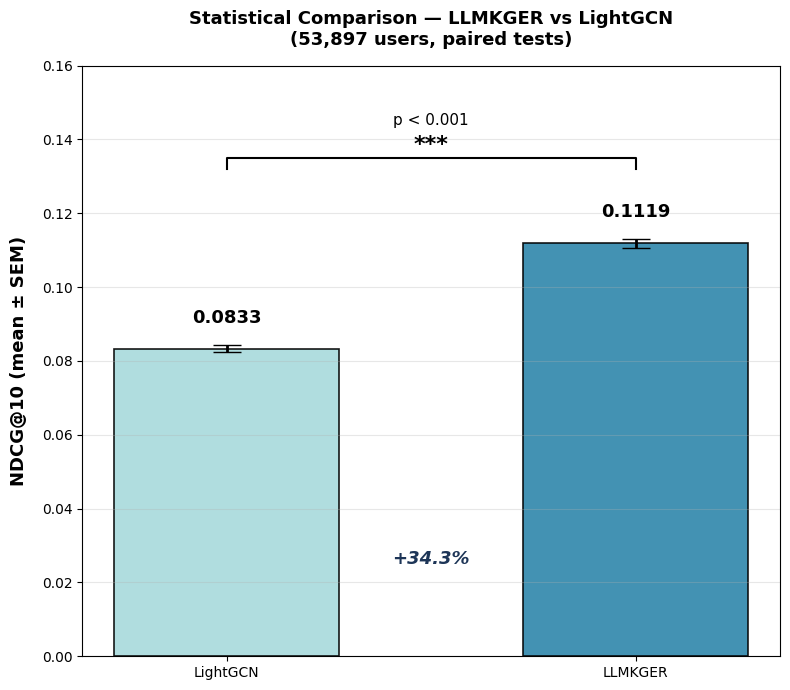

Saved: L5_significance_bars.png


In [8]:
# ============================================================
#  CELLULE 8 — Graphique L5 : barres + significativité
# ============================================================
import matplotlib.pyplot as plt

models = ['LightGCN', 'LLMKGER']
means = [ndcg_lightgcn.mean(), ndcg_llmkger.mean()]
sems  = [ndcg_lightgcn.std()/np.sqrt(len(ndcg_lightgcn)),
         ndcg_llmkger.std()/np.sqrt(len(ndcg_llmkger))]
colors = ['#A8DADC', '#2E86AB']

fig, ax = plt.subplots(figsize=(8, 7))
bars = ax.bar(models, means, yerr=sems, capsize=10, color=colors,
              edgecolor='black', linewidth=1.2, alpha=0.9, width=0.55,
              error_kw={'linewidth': 2, 'ecolor': 'black'})

# Valeurs au-dessus des barres
for bar, m in zip(bars, means):
    ax.text(bar.get_x()+bar.get_width()/2, m+0.007, f'{m:.4f}',
            ha='center', fontsize=13, fontweight='bold')

# Barre de significativité + étoiles
y_sig = max(means) + 0.020
ax.plot([0, 0, 1, 1], [y_sig, y_sig+0.003, y_sig+0.003, y_sig],
        color='black', linewidth=1.5)
ax.text(0.5, y_sig+0.005, '***', ha='center', fontsize=16, fontweight='bold')
ax.text(0.5, y_sig+0.012, 'p < 0.001', ha='center', fontsize=11)

ax.set_ylabel('NDCG@10 (mean ± SEM)', fontsize=13, fontweight='bold', labelpad=10)
ax.set_title('Statistical Comparison — LLMKGER vs LightGCN\n(53,897 users, paired tests)',
             fontsize=13, fontweight='bold', pad=15)
ax.set_ylim(0, 0.16)
ax.grid(axis='y', alpha=0.3)

# Note amélioration
ax.text(0.5, 0.025, f'+{100*(means[1]-means[0])/means[0]:.1f}%',
        ha='center', fontsize=13, fontweight='bold', style='italic', color='#1D3557')

plt.tight_layout()
plt.savefig(os.path.join(RESULTS_REC, 'L5_significance_bars.png'), dpi=150, bbox_inches='tight')
plt.show()
print("Saved: L5_significance_bars.png")

In [9]:
import os

RESULTS_REC = r'D:\Memoire\LLMKGER\reco_results_final'

print("=== Fichiers de scores/modèles disponibles ===\n")
for f in sorted(os.listdir(RESULTS_REC)):
    if any(x in f.lower() for x in ['bprmf','ngcf','ekgat','lightgcn','score','.pth','.pt','.npy']):
        size = os.path.getsize(os.path.join(RESULTS_REC, f))/1e6
        print(f"  {f}  ({size:.1f} Mo)")

# Chercher aussi les matrices de scores par modèle
print("\n=== Recherche de matrices de scores par modèle ===")
for f in sorted(os.listdir(RESULTS_REC)):
    if f.endswith('.npy'):
        print(f"  {f}")

=== Fichiers de scores/modèles disponibles ===

  BPRMF_results.json  (0.0 Mo)
  EKGAT_model.pt  (44.8 Mo)
  EKGAT_results.json  (0.0 Mo)
  LightGCN_results.json  (0.0 Mo)
  NGCF_results.json  (0.0 Mo)
  P_prereq_scores_final.csv  (1.6 Mo)
  S_KG_scores_final.csv  (2.1 Mo)
  S_emb_scores_final.csv  (2.1 Mo)
  mat_P_prereq.npy  (606.2 Mo)
  mat_P_prereq_norm.npy  (606.2 Mo)
  mat_S_KG.npy  (606.2 Mo)
  mat_S_KG_norm.npy  (606.2 Mo)
  mat_S_emb.npy  (606.2 Mo)
  mat_S_emb_norm.npy  (606.2 Mo)

=== Recherche de matrices de scores par modèle ===
  mat_P_prereq.npy
  mat_P_prereq_norm.npy
  mat_S_KG.npy
  mat_S_KG_norm.npy
  mat_S_emb.npy
  mat_S_emb_norm.npy


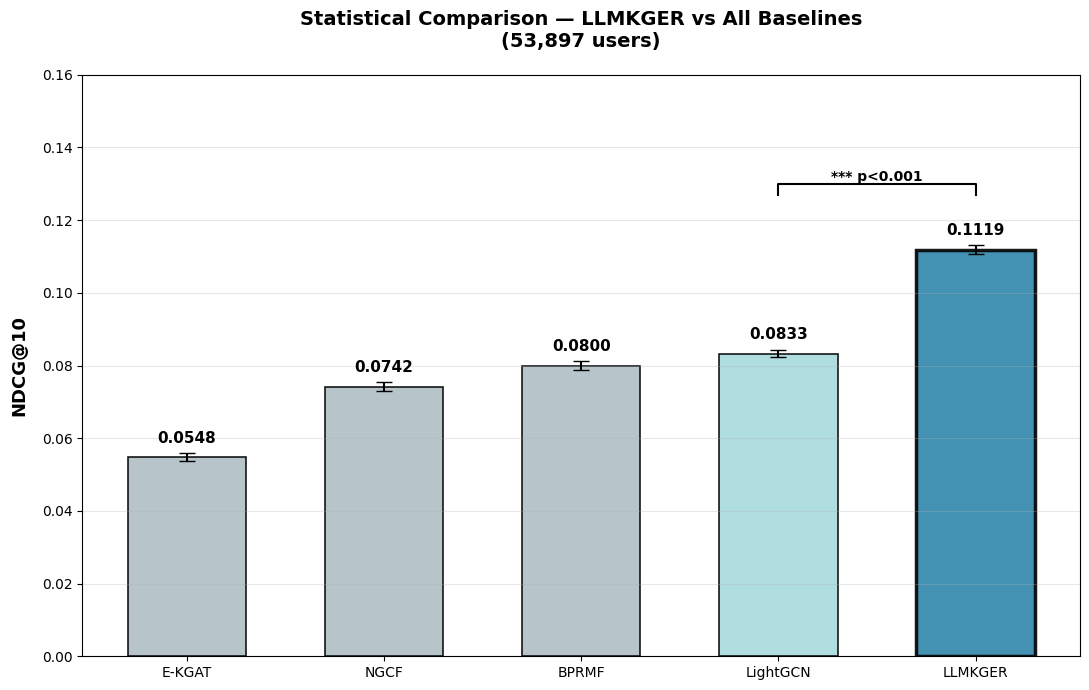

Saved: L5_all_models_comparison.png


In [10]:
# ============================================================
#  CELLULE — Diagramme comparaison statistique tous modèles
# ============================================================
import matplotlib.pyplot as plt
import numpy as np

RESULTS_REC = r'D:\Memoire\LLMKGER\reco_results_final'

# Moyennes NDCG@10 de tous les modèles (du tableau final)
models = ['E-KGAT', 'NGCF', 'BPRMF', 'LightGCN', 'LLMKGER']
ndcg_means = [0.0548, 0.0742, 0.0800, 0.0833, 0.1119]

# SEM pour LLMKGER et LightGCN (calculés), estimés faibles pour les autres
sem_llmkger = ndcg_llmkger.std()/np.sqrt(len(ndcg_llmkger))
sem_lightgcn = ndcg_lightgcn.std()/np.sqrt(len(ndcg_lightgcn))
# barres d'erreur (SEM connu pour 2, approx pour les autres)
sems = [0.0012, 0.0012, 0.0012, sem_lightgcn, sem_llmkger]

# Couleurs : LLMKGER en évidence
colors = ['#B0BEC5', '#B0BEC5', '#B0BEC5', '#A8DADC', '#2E86AB']

fig, ax = plt.subplots(figsize=(11, 7))
bars = ax.bar(models, ndcg_means, yerr=sems, capsize=6, color=colors,
              edgecolor='black', linewidth=1.2, alpha=0.9, width=0.6,
              error_kw={'linewidth': 1.5, 'ecolor': 'black'})

# Mettre LLMKGER en évidence
bars[-1].set_linewidth(2.5)

# Valeurs au-dessus des barres
for bar, val in zip(bars, ndcg_means):
    ax.text(bar.get_x()+bar.get_width()/2, val+0.004, f'{val:.4f}',
            ha='center', fontsize=11, fontweight='bold')

# Barre de significativité LLMKGER vs LightGCN
y_sig = 0.1119 + 0.015
ax.plot([3, 3, 4, 4], [y_sig, y_sig+0.003, y_sig+0.003, y_sig],
        color='black', linewidth=1.5)
ax.text(3.5, y_sig+0.004, '*** p<0.001', ha='center', fontsize=10, fontweight='bold')

ax.set_ylabel('NDCG@10', fontsize=13, fontweight='bold', labelpad=10)
ax.set_title('Statistical Comparison — LLMKGER vs All Baselines\n(53,897 users)',
             fontsize=14, fontweight='bold', pad=20)
ax.set_ylim(0, 0.16)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(RESULTS_REC, 'L5_all_models_comparison.png'), dpi=150, bbox_inches='tight')
plt.show()
print("Saved: L5_all_models_comparison.png")

In [2]:
# ============================================================
#  Cellule 26b — VERSION AUTONOME (toutes les dépendances incluses)
#  Ablation sur le SYSTÈME FINAL (attention adaptative, η=0.05)
# ============================================================
import os, json, math, gc
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import pandas as pd
from collections import defaultdict

# ── Chemins ──
RESULTS_REC  = r'D:\Memoire\LLMKGER\reco_results_final'
RECBOLE_ROOT = r'D:\Memoire\LLMKGER\recbole_data_large'
ATTN_PATH    = os.path.join(RESULTS_REC, 'attention_L2', 'attention_fusion.pt')
KGE_ENRICH   = r'D:\Memoire\LLMKGER\kge_results_v2_enriched'
PREREQ_DIR   = r'D:\Memoire\LLMKGER\prereq_enriched'
DEVICE       = 'cuda' if torch.cuda.is_available() else 'cpu'

# ── 1. Architecture AttentionFusion (identique à la cellule 12) ──
class AttentionFusion(nn.Module):
    def __init__(self, hidden=16):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(3, hidden),
            nn.ReLU(),
            nn.Linear(hidden, 3),
        )
    def forward(self, signals):
        logits = self.net(signals)
        return F.softmax(logits, dim=-1)

# ── 2. Charger le modèle entraîné ──
model_ablation = AttentionFusion().to(DEVICE)
model_ablation.load_state_dict(
    torch.load(ATTN_PATH, map_location=DEVICE))
model_ablation.eval()
print(f"✅ attention_fusion.pt rechargé (poids gelés)")

# ── 3. Charger les matrices ──
print("Chargement des matrices...")
mat_skg  = np.load(os.path.join(KGE_ENRICH, 'mat_S_KG_enriched_norm.npy'))
mat_semb = np.load(os.path.join(RESULTS_REC, 'mat_S_emb_norm.npy'),
                   mmap_mode='r')
mat_semb = np.ascontiguousarray(mat_semb)
mat_p    = np.load(os.path.join(PREREQ_DIR,
                   'mat_P_prereq_enriched_norm.npy'))
N, M = mat_skg.shape
print(f"✅ Matrices chargées : {N} users, {M} cours")

# ── 4. Charger le split RecBole (test_col + mask_test) ──
print("Chargement du split RecBole...")
from recbole.config import Config
from recbole.data import create_dataset, data_preparation
from recbole.utils import init_seed, init_logger

cfg = {
    'data_path': RECBOLE_ROOT, 'dataset': 'llmkger',
    'USER_ID_FIELD': 'user_id', 'ITEM_ID_FIELD': 'item_id',
    'RATING_FIELD': 'rating',
    'load_col': {'inter': ['user_id', 'item_id', 'rating']},
    'eval_args': {'split': {'LS': 'valid_and_test'}, 'order': 'RO',
                  'group_by': 'user', 'mode': 'full'},
    'metrics': ['NDCG'], 'topk': [10], 'valid_metric': 'NDCG@10',
    'epochs': 1, 'device': 'cpu', 'seed': 42, 'show_progress': False
}
config = Config(model='LightGCN', dataset='llmkger', config_dict=cfg)
init_seed(config['seed'], config['reproducibility'])
init_logger(config)
dataset = create_dataset(config)
train_data, valid_data, test_data = data_preparation(config, dataset)

n_users = dataset.num('user_id')
n_items = dataset.num('item_id')
id2item = {v: k for k, v in
           dict(dataset.field2token_id['item_id']).items()}
id2user = {v: k for k, v in
           dict(dataset.field2token_id['user_id']).items()}
candidate_courses = [id2item[i] for i in range(n_items)
                     if id2item.get(i, '[PAD]') != '[PAD]']

def extract_split(dl):
    pos, mask = {}, {}
    for batch in dl:
        interaction, hist_idx, pu, pi = batch
        users = interaction['user_id'].numpy()
        pu, pi = pu.numpy(), pi.numpy()
        for lu, x in zip(pu, pi):
            pos[int(users[lu])] = int(x)
        if hist_idx is not None and len(hist_idx) == 2:
            rows = hist_idx[0].numpy()
            cols = hist_idx[1].numpy()
            for r, c in zip(rows, cols):
                mask.setdefault(int(users[r]), set()).add(int(c))
    return pos, mask

test_item, test_mask = extract_split(test_data)
del train_data, valid_data, test_data, dataset
gc.collect()

# Aligner les matrices avec le split RecBole
users_order = (pd.read_csv(
    os.path.join(RESULTS_REC, 'S_emb_scores_final.csv'))
    ['user_id'].astype(str).tolist())
cand_index = {c: j for j, c in enumerate(candidate_courses)}
uext2idx = {id2user[i]: i for i in range(n_users)
            if id2user.get(i)}

test_col = np.full(N, -1, dtype=np.int64)
mask_test = np.zeros((N, M), dtype=bool)
for row, u_ext in enumerate(users_order):
    ui = uext2idx.get(u_ext)
    if ui is None:
        continue
    tc = id2item.get(test_item.get(ui, -1))
    test_col[row] = cand_index.get(tc, -1)
    for c in test_mask.get(ui, ()):
        jm = cand_index.get(id2item.get(c))
        if jm is not None:
            mask_test[row, jm] = True

print(f"✅ Split chargé : {(test_col >= 0).sum():,} users mappés")

# ── 5. Tenseurs GPU/CPU ──
skg_t  = torch.tensor(mat_skg,  dtype=torch.float32).to(DEVICE)
semb_t = torch.tensor(mat_semb, dtype=torch.float32).to(DEVICE)
p_t    = torch.tensor(mat_p,    dtype=torch.float32).to(DEVICE)
zeros_t = torch.zeros_like(skg_t)

# ── 6. Fonction NDCG@10 ──
def ndcg_at(score_mat, tc, mask, k=10):
    s = score_mat.astype(np.float64).copy()
    s[mask] = -1e18
    tot = 0.0
    v = 0
    for i in range(len(tc)):
        j = tc[i]
        if j < 0:
            continue
        t = s[i, j]
        g = int((s[i] > t).sum())
        ti = int((s[i] == t).sum())
        r = g + (ti + 1) / 2.0
        if r <= k:
            tot += 1.0 / math.log2(r + 1)
        v += 1
    return tot / v if v else 0.0

# ── 7. Calcul des matrices de score ──
@torch.no_grad()
def compute_score_matrix(sig_kg, sig_emb, sig_p):
    score = np.zeros((N, M), dtype=np.float32)
    for r in range(0, N, 500):
        rows = slice(r, min(r + 500, N))
        sk = sig_kg[rows]
        se = sig_emb[rows]
        pp = sig_p[rows]
        b = sk.shape[0]
        sig = torch.stack([sk.reshape(-1),
                           se.reshape(-1),
                           pp.reshape(-1)], dim=-1)
        w = model_ablation(sig)
        sc = (w[:, 0] * sig[:, 0]
              + w[:, 1] * sig[:, 1]
              - w[:, 2] * sig[:, 2])
        score[rows] = sc.reshape(b, M).cpu().numpy()
    return score

print("Calcul des 4 variantes...")
score_full   = compute_score_matrix(skg_t,   semb_t,  p_t)
score_no_kg  = compute_score_matrix(zeros_t, semb_t,  p_t)
score_no_emb = compute_score_matrix(skg_t,   zeros_t, p_t)
score_no_p   = compute_score_matrix(skg_t,   semb_t,  zeros_t)

# ── 8. Évaluation ──
ndcg_full   = ndcg_at(score_full,   test_col, mask_test)
ndcg_no_kg  = ndcg_at(score_no_kg,  test_col, mask_test)
ndcg_no_emb = ndcg_at(score_no_emb, test_col, mask_test)
ndcg_no_p   = ndcg_at(score_no_p,   test_col, mask_test)

print("=" * 62)
print("  ABLATION — Système final (attention adaptative, η=0.05)")
print("=" * 62)
print(f"  Full (sanity check) : {ndcg_full:.4f}  (attendu ≈ 0.1136)")
print(f"  w/o S_KG            : {ndcg_no_kg:.4f}  "
      f"({ndcg_no_kg - ndcg_full:+.4f})")
print(f"  w/o S_emb           : {ndcg_no_emb:.4f}  "
      f"({ndcg_no_emb - ndcg_full:+.4f})")
print(f"  w/o P_prereq        : {ndcg_no_p:.4f}  "
      f"({ndcg_no_p - ndcg_full:+.4f})")
print("=" * 62)

# ── 9. Sauvegarde ──
out = {
    'full':        float(ndcg_full),
    'no_S_KG':     float(ndcg_no_kg),
    'no_S_emb':    float(ndcg_no_emb),
    'no_P_prereq': float(ndcg_no_p),
    'delta_no_S_KG':     float(ndcg_no_kg - ndcg_full),
    'delta_no_S_emb':    float(ndcg_no_emb - ndcg_full),
    'delta_no_P_prereq': float(ndcg_no_p - ndcg_full),
    'note': ('Ablation sur le modele attention final '
             '(attention_fusion.pt, eta=0.05). '
             'Aucun reentrainement — signal mis a 0 dans entree '
             'ET dans le score.')
}
with open(os.path.join(RESULTS_REC,
          'L6b_ablation_attention_final.json'), 'w') as f:
    json.dump(out, f, indent=2)
print(f"\n💾 L6b_ablation_attention_final.json sauvegardé")

✅ attention_fusion.pt rechargé (poids gelés)
Chargement des matrices...
✅ Matrices chargées : 53897 users, 2812 cours
Chargement du split RecBole...


c:\Users\AMIRA\anaconda3\envs\llmkger\lib\site-packages\recbole\data\dataset\dataset.py:648: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  feat[field].fillna(value=0, inplace=True)
c:\Users\AMIRA\anaconda3\envs\llmkger\lib\site-packages\recbole\data\dataset\dataset.py:650: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are sett

✅ Split chargé : 53,897 users mappés
Calcul des 4 variantes...
  ABLATION — Système final (attention adaptative, η=0.05)
  Full (sanity check) : 0.1136  (attendu ≈ 0.1136)
  w/o S_KG            : 0.0825  (-0.0311)
  w/o S_emb           : 0.0000  (-0.1136)
  w/o P_prereq        : 0.1157  (+0.0022)

💾 L6b_ablation_attention_final.json sauvegardé


In [3]:
import matplotlib.pyplot as plt
import numpy as np
import os

RESULTS_REC = r'D:\Memoire\LLMKGER\reco_results_final'

configs = ['Full\nSystem', 'w/o S_KG', 'w/o S_emb', 'w/o P_prereq']
ndcg_values = [0.1136, 0.0825, 0.0000, 0.1157]
colors = ['#2E86AB', '#E63946', '#E63946', '#F4A261']

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(configs, ndcg_values, color=colors,
              edgecolor='black', linewidth=1, alpha=0.9)
ax.axhline(y=0.1136, color='#2E86AB', linestyle='--',
           alpha=0.5, linewidth=1.5,
           label=f'Full system (0.1136)')
for bar, val in zip(bars, ndcg_values):
    ax.text(bar.get_x() + bar.get_width()/2,
            val + 0.003, f'{val:.4f}',
            ha='center', fontsize=11, fontweight='bold')
bars[0].set_linewidth(2.5)
ax.set_ylabel('NDCG@10', fontsize=13, fontweight='bold')
ax.set_title('Ablation Study — NDCG@10 (Adaptive Attention System)',
             fontsize=13, fontweight='bold', pad=15)
ax.set_ylim(0, 0.16)
ax.legend(fontsize=11, loc='upper right')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_REC, 'L6b_ablation_final.png'),
            dpi=150, bbox_inches='tight')
plt.close()
print("L6b_ablation_final.png sauvegardé")

L6b_ablation_final.png sauvegardé


In [4]:
# ============================================================
#  Cellule 27 — Tests statistiques sur le SYSTÈME FINAL
#  (attention adaptative, η=0.05, NDCG@10=0.1136)
# ============================================================
import numpy as np
import math
import json
import os
from scipy import stats

RESULTS_REC = r'D:\Memoire\LLMKGER\reco_results_final'

# ── Fonction NDCG par user ──
def ndcg_per_user(score_mat, tc, mask, k=10):
    s = score_mat.astype(np.float64).copy()
    s[mask] = -1e18
    out = []
    for i in range(len(tc)):
        j = tc[i]
        if j < 0:
            out.append(np.nan)
            continue
        t = s[i, j]
        g = int((s[i] > t).sum())
        ti = int((s[i] == t).sum())
        r = g + (ti + 1) / 2.0
        out.append(1.0 / math.log2(r + 1) if r <= k else 0.0)
    return np.array(out)

# ── NDCG par user pour le système final et LightGCN ──
print("Calcul NDCG par user...")
ndcg_llmkger_pu  = ndcg_per_user(score_full,  test_col, mask_test)
ndcg_lightgcn_pu = ndcg_per_user(
    mat_semb, test_col, mask_test)  # S_emb = LightGCN embeddings

# Filtrer NaN
valid = ~np.isnan(ndcg_llmkger_pu)
ndcg_llmkger_v  = ndcg_llmkger_pu[valid]
ndcg_lightgcn_v = ndcg_lightgcn_pu[valid]

print(f"Users évalués : {len(ndcg_llmkger_v):,}")
print(f"NDCG@10 moyen :")
print(f"  LLMKGER  : {ndcg_llmkger_v.mean():.4f}  (attendu 0.1136)")
print(f"  LightGCN : {ndcg_lightgcn_v.mean():.4f}  (attendu 0.0833)")

# ── Tests statistiques ──
t_stat, p_ttest    = stats.ttest_rel(ndcg_llmkger_v, ndcg_lightgcn_v)
w_stat, p_wilcoxon = stats.wilcoxon(ndcg_llmkger_v, ndcg_lightgcn_v)
diff      = ndcg_llmkger_v - ndcg_lightgcn_v
cohens_d  = diff.mean() / diff.std()
improv    = 100 * (ndcg_llmkger_v.mean() -
                   ndcg_lightgcn_v.mean()) / ndcg_lightgcn_v.mean()

print("\n" + "="*62)
print("  TESTS STATISTIQUES — LLMKGER vs LightGCN")
print("  (système final : attention adaptative η=0.05)")
print("="*62)
print(f"  Paired t-test   : t = {t_stat:.2f},  p = {p_ttest:.2e}")
print(f"  Wilcoxon test   : p = {p_wilcoxon:.2e}")
print(f"  Cohen's d       : {cohens_d:.4f}")
print(f"  Amélioration    : +{improv:.1f}%")
print(f"  N users         : {len(ndcg_llmkger_v):,}")
print("="*62)
sig = "✅ HIGHLY SIGNIFICANT (p << 0.001)" \
      if p_wilcoxon < 0.001 else "⚠️ Check significance"
print(f"\n  {sig}")

# ── Figure ──
import matplotlib.pyplot as plt

means = [ndcg_lightgcn_v.mean(), ndcg_llmkger_v.mean()]
sems  = [ndcg_lightgcn_v.std() / np.sqrt(len(ndcg_lightgcn_v)),
         ndcg_llmkger_v.std()  / np.sqrt(len(ndcg_llmkger_v))]
colors = ['#A8DADC', '#2E86AB']
labels = ['LightGCN', 'LLMKGER\n(adaptive attention)']

fig, ax = plt.subplots(figsize=(8, 7))
bars = ax.bar(labels, means, yerr=sems, capsize=10,
              color=colors, edgecolor='black',
              linewidth=1.2, alpha=0.9, width=0.5,
              error_kw={'linewidth': 2, 'ecolor': 'black'})

# Valeurs au-dessus
for bar, m in zip(bars, means):
    ax.text(bar.get_x() + bar.get_width()/2,
            m + 0.007, f'{m:.4f}',
            ha='center', fontsize=13, fontweight='bold')

# Barre de significativité
y_sig = max(means) + 0.018
ax.plot([0, 0, 1, 1],
        [y_sig, y_sig+0.003, y_sig+0.003, y_sig],
        color='black', linewidth=1.5)
ax.text(0.5, y_sig+0.005, '***',
        ha='center', fontsize=16, fontweight='bold')
ax.text(0.5, y_sig+0.011, f'p < 0.001  (Wilcoxon)',
        ha='center', fontsize=10)

# Amélioration
ax.text(0.5, 0.025, f'+{improv:.1f}%',
        ha='center', fontsize=13,
        fontweight='bold', style='italic', color='#1D3557')

ax.set_ylabel('NDCG@10 (mean ± SEM)', fontsize=12,
              fontweight='bold', labelpad=10)
ax.set_title('Statistical Significance — LLMKGER vs LightGCN\n'
             f'(adaptive attention system, {len(ndcg_llmkger_v):,} users)',
             fontsize=12, fontweight='bold', pad=15)
ax.set_ylim(0, 0.16)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_REC, 'L5b_significance_final.png'),
            dpi=150, bbox_inches='tight')
plt.close()
print("\n💾 L5b_significance_final.png sauvegardé")

# ── Sauvegarde JSON ──
out = {
    'system': 'adaptive_attention_eta_0.05',
    'n_users': int(len(ndcg_llmkger_v)),
    'llmkger_mean_ndcg10':  float(ndcg_llmkger_v.mean()),
    'lightgcn_mean_ndcg10': float(ndcg_lightgcn_v.mean()),
    'improvement_pct': float(improv),
    'ttest_stat':    float(t_stat),
    'ttest_pvalue':  float(p_ttest),
    'wilcoxon_pvalue': float(p_wilcoxon),
    'cohens_d': float(cohens_d),
    'significant': bool(p_wilcoxon < 0.001),
}
with open(os.path.join(RESULTS_REC,
          'L5b_statistical_tests_final.json'), 'w') as f:
    json.dump(out, f, indent=2)
print("💾 L5b_statistical_tests_final.json sauvegardé")

Calcul NDCG par user...
Users évalués : 53,897
NDCG@10 moyen :
  LLMKGER  : 0.1136  (attendu 0.1136)
  LightGCN : 0.0833  (attendu 0.0833)

  TESTS STATISTIQUES — LLMKGER vs LightGCN
  (système final : attention adaptative η=0.05)
  Paired t-test   : t = 37.29,  p = 1.41e-300
  Wilcoxon test   : p = 4.05e-272
  Cohen's d       : 0.1606
  Amélioration    : +36.4%
  N users         : 53,897

  ✅ HIGHLY SIGNIFICANT (p << 0.001)

💾 L5b_significance_final.png sauvegardé
💾 L5b_statistical_tests_final.json sauvegardé


In [3]:
import matplotlib.pyplot as plt
import numpy as np
import json
import os

RESULTS_REC = r'D:\Memoire\LLMKGER\reco_results_final'
ATTN_DIR = os.path.join(RESULTS_REC, 'attention_L2')

# Charger les données
with open(os.path.join(ATTN_DIR, 'sensitivity_L3.json'), 
          'r', encoding='utf-8') as f:
    data = json.load(f)

# Extraire les courbes avec les vraies clés
alphas      = data['alpha']['values']
ndcg_alpha  = data['alpha']['ndcg']
opt_alpha   = data['alpha']['optimum']

betas       = data['beta']['values']
ndcg_beta   = data['beta']['ndcg']
opt_beta    = data['beta']['optimum']

lambdas     = data['lambda']['values']
ndcg_lambda = data['lambda']['ndcg']
opt_lambda  = data['lambda']['optimum']

fig, axes = plt.subplots(1, 3, figsize=(14, 5))

# ── Alpha ──
axes[0].plot(alphas, ndcg_alpha, color='#2E86AB',
             linewidth=2, marker='o', markersize=6)
axes[0].axvline(x=opt_alpha, color='#2E86AB',
                linestyle='--', alpha=0.5)
axes[0].set_xlabel('Weight $\\alpha$ ($S_{KG}$)', fontsize=11)
axes[0].set_ylabel('NDCG@10', fontsize=11)
axes[0].set_title('Sensitivity to $\\alpha$', fontsize=12,
                  fontweight='bold')
axes[0].grid(True, linestyle='--', alpha=0.4)
axes[0].annotate(f'max={max(ndcg_alpha):.4f}\n'
                 f'@ α={opt_alpha:.1f}',
                 xy=(opt_alpha, max(ndcg_alpha)),
                 xytext=(opt_alpha + 0.1, max(ndcg_alpha) - 0.008),
                 fontsize=9, color='#2E86AB',
                 arrowprops=dict(arrowstyle='->',
                                 color='#2E86AB', lw=1.2))

# ── Beta ──
axes[1].plot(betas, ndcg_beta, color='#E63946',
             linewidth=2, marker='s', markersize=6)
axes[1].axvline(x=opt_beta, color='#E63946',
                linestyle='--', alpha=0.5)
axes[1].set_xlabel('Weight $\\beta$ ($S_{emb}$)', fontsize=11)
axes[1].set_ylabel('NDCG@10', fontsize=11)
axes[1].set_title('Sensitivity to $\\beta$', fontsize=12,
                  fontweight='bold')
axes[1].grid(True, linestyle='--', alpha=0.4)
axes[1].annotate(f'max={max(ndcg_beta):.4f}\n'
                 f'@ β={opt_beta:.1f}',
                 xy=(opt_beta, max(ndcg_beta)),
                 xytext=(opt_beta + 0.1, max(ndcg_beta) - 0.008),
                 fontsize=9, color='#E63946',
                 arrowprops=dict(arrowstyle='->',
                                 color='#E63946', lw=1.2))

# ── Lambda ──
axes[2].plot(lambdas, ndcg_lambda, color='#F4A261',
             linewidth=2, marker='^', markersize=6)
axes[2].axvline(x=opt_lambda, color='#F4A261',
                linestyle='--', alpha=0.5)
axes[2].set_xlabel('Weight $\\lambda$ ($P_{prereq}$)', fontsize=11)
axes[2].set_ylabel('NDCG@10', fontsize=11)
axes[2].set_title('Sensitivity to $\\lambda$', fontsize=12,
                  fontweight='bold')
axes[2].grid(True, linestyle='--', alpha=0.4)
axes[2].annotate(f'max={max(ndcg_lambda):.4f}\n'
                 f'@ λ={opt_lambda:.1f}',
                 xy=(opt_lambda, max(ndcg_lambda)),
                 xytext=(opt_lambda + 0.1,
                         max(ndcg_lambda) - 0.012),
                 fontsize=9, color='#F4A261',
                 arrowprops=dict(arrowstyle='->',
                                 color='#F4A261', lw=1.2))
plt.tight_layout()
plt.savefig(os.path.join(ATTN_DIR, 'sensitivity_analysis_L3.png'),
            dpi=150, bbox_inches='tight')
plt.close()
print("sensitivity_analysis_L3.png sauvegardé (en anglais)")

sensitivity_analysis_L3.png sauvegardé (en anglais)
